In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

EDA
1. Initial Data Understanding

. Data Loading and Inspection

· Data Types

· Missing Values

· Duplicates

In [2]:
data = pd.read_csv("./car_price_prediction.csv")
data.head()


,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [3]:
data.shape

(19237, 18)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19237 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                19237 non-null  int64  
 1   Price             19237 non-null  int64  
 2   Levy              19237 non-null  object 
 3   Manufacturer      19237 non-null  object 
 4   Model             19237 non-null  object 
 5   Prod. year        19237 non-null  int64  
 6   Category          19237 non-null  object 
 7   Leather interior  19237 non-null  object 
 8   Fuel type         19237 non-null  object 
 9   Engine volume     19237 non-null  object 
 10  Mileage           19237 non-null  object 
 11  Cylinders         19237 non-null  float64
 12  Gear box type     19237 non-null  object 
 13  Drive wheels      19237 non-null  object 
 14  Doors             19237 non-null  object 
 15  Wheel             19237 non-null  object 
 16  Color             19237 non-null  object

In [5]:
data.isna().sum()

ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

In [6]:
data.duplicated().sum()

np.int64(313)

In [7]:
data.drop_duplicates(inplace=True)                                                                  

In [8]:
data.shape

(18924, 18)

2.Basic Statistical Overview

. Summary Statistics (describe(), value_counts())
· Zero and Constant Values




In [9]:
data.describe()

,ID,Price,Prod. year,Cylinders,Airbags
count,1.892400e+04,1.892400e+04,18924.000000,18924.000000,18924.000000
mean,4.557538e+07,1.858744e+04,2010.914236,4.580216,6.568379
std,9.375468e+05,1.921356e+05,5.665749,1.200223,4.322323
min,2.074688e+07,1.000000e+00,1939.000000,1.000000,0.000000
25%,4.569501e+07,5.331000e+03,2009.000000,4.000000,4.000000
50%,4.577191e+07,1.317200e+04,2012.000000,4.000000,6.000000
75%,4.580174e+07,2.206300e+04,2015.000000,4.000000,12.000000
max,4.581665e+07,2.630750e+07,2020.000000,16.000000,16.000000


In [10]:
data.select_dtypes(include='object').describe()

,Levy,Manufacturer,Model,Category,Leather interior,Fuel type,Engine volume,Mileage,Gear box type,Drive wheels,Doors,Wheel,Color
count,18924,18924,18924,18924,18924,18924,18924,18924,18924,18924,18924,18924,18924
unique,559,65,1590,11,2,7,107,7687,4,3,3,2,16
top,-,HYUNDAI,Prius,Sedan,Yes,Petrol,2,0 km,Automatic,Front,04-May,Left wheel,Black
freq,5709,3729,1069,8600,13731,9944,3856,714,13282,12695,18032,17471,4944


In [11]:
def top_and_bottom_combined(df, col, n=5):
    top_counts = df[col].value_counts().head(n)
    bottom_counts = df[col].value_counts().tail(n)

    combined = pd.concat([top_counts, bottom_counts], axis=0)
    combined.columns = ['Most Frequent', 'Least Frequent']
    return combined

for col in data.select_dtypes(include='object'):
    print(f'{col} value counts:')
    print(top_and_bottom_combined(data, col))
    print('30 Unique values:', data[col].unique()[:30])
    print('---' * 20)
    

Levy value counts:
Levy
-       5709
765      482
891      453
639      403
640      398
4741       1
841        1
1369       1
5681       1
3112       1
Name: count, dtype: int64
30 Unique values: ['1399' '1018' '-' '862' '446' '891' '761' '751' '394' '1053' '1055'
 '1079' '810' '2386' '1850' '531' '586' '1249' '2455' '583' '1537' '1288'
 '915' '1750' '707' '1077' '1486' '1091' '650' '382']
------------------------------------------------------------
Manufacturer value counts:
Manufacturer
HYUNDAI          3729
TOYOTA           3606
MERCEDES-BENZ    2043
FORD             1088
CHEVROLET        1047
LAMBORGHINI         1
PONTIAC             1
SATURN              1
ASTON MARTIN        1
GREATWALL           1
Name: count, dtype: int64
30 Unique values: ['LEXUS' 'CHEVROLET' 'HONDA' 'FORD' 'HYUNDAI' 'TOYOTA' 'MERCEDES-BENZ'
 'OPEL' 'PORSCHE' 'BMW' 'JEEP' 'VOLKSWAGEN' 'AUDI' 'RENAULT' 'NISSAN'
 'SUBARU' 'DAEWOO' 'KIA' 'MITSUBISHI' 'SSANGYONG' 'MAZDA' 'GMC' 'FIAT'
 'INFINITI' 'ALFA ROMEO' 'SU

Mileage
0 km         714
200000 km    181
150000 km    159
160000 km    120
180000 km    117
130412 km      1
71991 km       1
70941 km       1
23474 km       1
62200 km       1
Name: count, dtype: int64
30 Unique values: ['186005 km' '192000 km' '200000 km' '168966 km' '91901 km' '160931 km'
 '258909 km' '216118 km' '398069 km' '128500 km' '184467 km' '0 km'
 '350000 km' '138038 km' '76000 km' '74146 km' '121840 km' '54317 km'
 '295059 km' '364523 km' '112645 km' '187000 km' '39709 km' '230000 km'
 '210000 km' '169000 km' '158787 km' '420550 km' '180000 km' '175056 km']
------------------------------------------------------------
Gear box type value counts:
Gear box type
Automatic    13282
Tiptronic     3065
Manual        1844
Variator       733
Automatic    13282
Tiptronic     3065
Manual        1844
Variator       733
Name: count, dtype: int64
30 Unique values: ['Automatic' 'Tiptronic' 'Variator' 'Manual']
------------------------------------------------------------
Drive wheels val

In [12]:
data['Levy'].replace({'-': 0}, inplace=True)
data['Levy'] = pd.to_numeric(data['Levy'])

C:\Users\somai\AppData\Local\Temp\ipykernel_11780\10418258.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['Levy'].replace({'-': 0}, inplace=True)


In [13]:
data['Engine volume'] = data['Engine volume'].str.replace('Turbo', '')
data['Engine volume'] = pd.to_numeric(data['Engine volume'])

In [14]:
data['Mileage'] = data['Mileage'].str.replace(' km', '')
data['Mileage'] = pd.to_numeric(data['Mileage'])

In [15]:
data.drop(['Doors'], axis=1, inplace=True)

In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18924 entries, 0 to 19236
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                18924 non-null  int64  
 1   Price             18924 non-null  int64  
 2   Levy              18924 non-null  int64  
 3   Manufacturer      18924 non-null  object 
 4   Model             18924 non-null  object 
 5   Prod. year        18924 non-null  int64  
 6   Category          18924 non-null  object 
 7   Leather interior  18924 non-null  object 
 8   Fuel type         18924 non-null  object 
 9   Engine volume     18924 non-null  float64
 10  Mileage           18924 non-null  int64  
 11  Cylinders         18924 non-null  float64
 12  Gear box type     18924 non-null  object 
 13  Drive wheels      18924 non-null  object 
 14  Wheel             18924 non-null  object 
 15  Color             18924 non-null  object 
 16  Airbags           18924 non-null  int64  
dty

3. Distribution of Variables

· Numerical Features (histograms, KDE)
· Categorical Features (bar plots, check imbalancement)
. Outlier detection


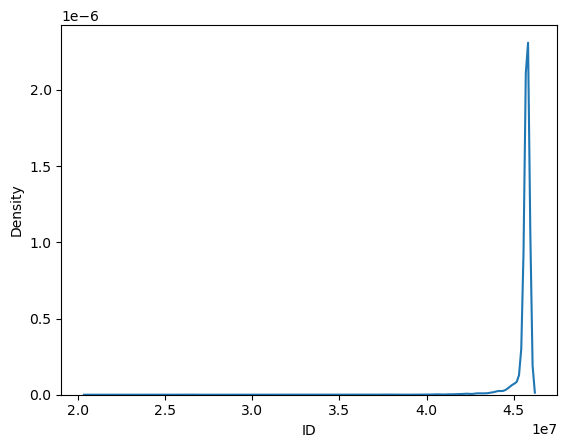

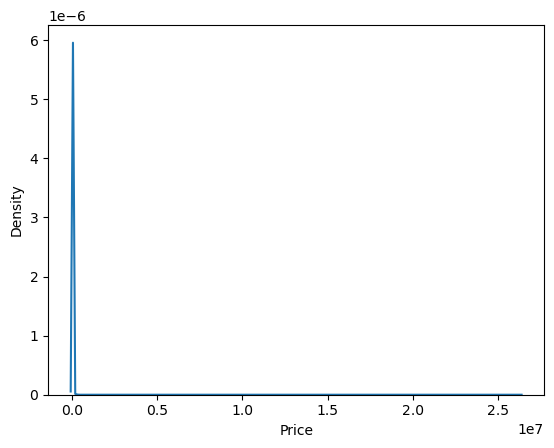

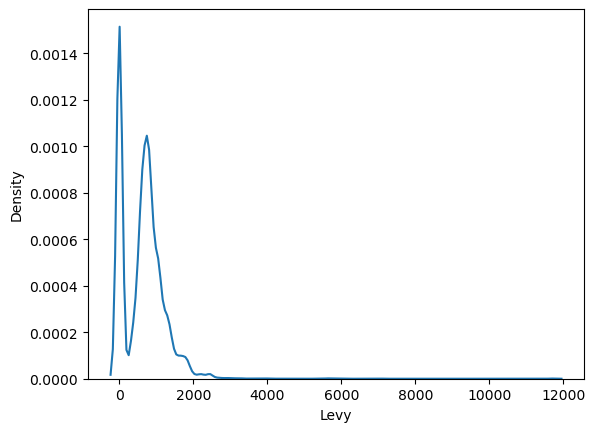

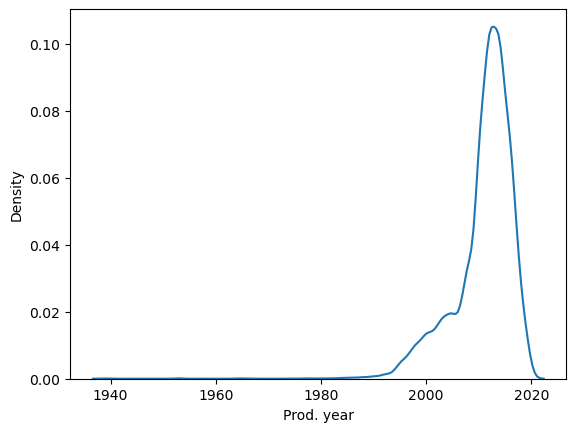

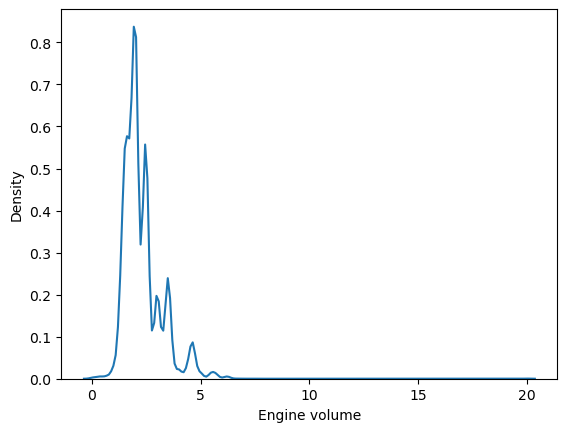

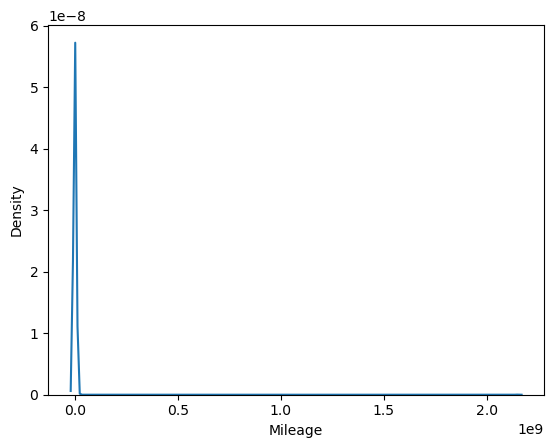

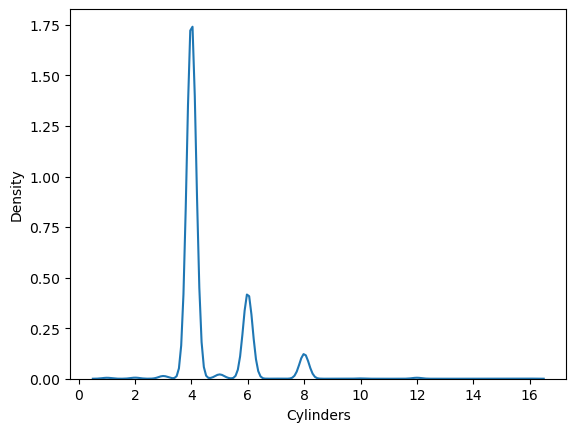

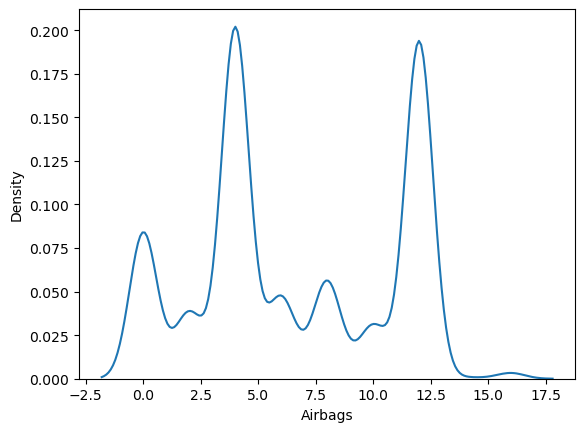

In [18]:
for col in data.select_dtypes('number').columns:
    sns.kdeplot(data[col])
    plt.show()

c:\Users\somai\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


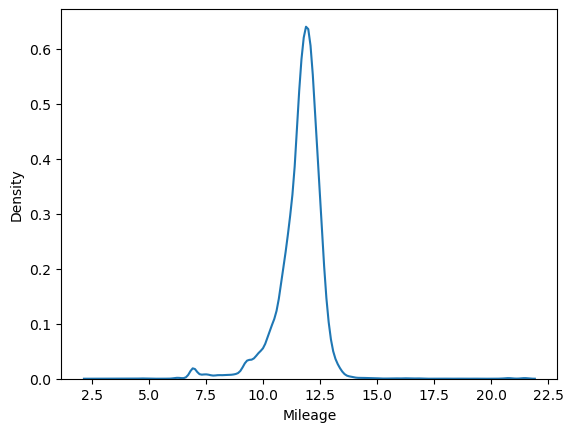

In [19]:
sns.kdeplot(np.log(data['Mileage']))
plt.show()

4. Correlations

· Numerical Correlations (corr())
· Categorical Correlations

<Axes: >

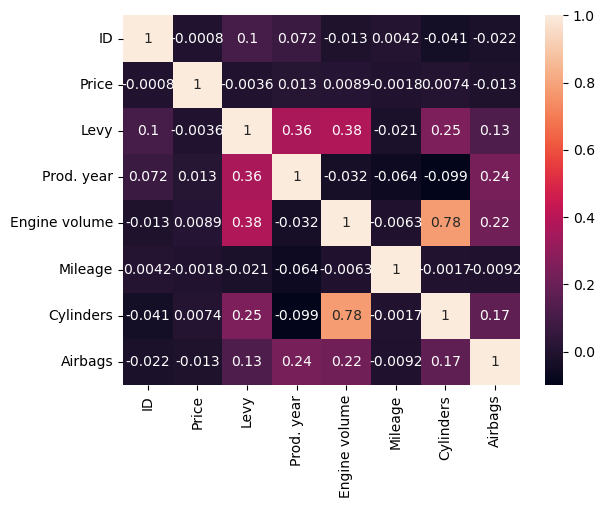

In [26]:
numeric_data = data.select_dtypes(include='number')
sns.heatmap(numeric_data.corr() , annot=True)

5. Feature Interactions

· Scatter Plots

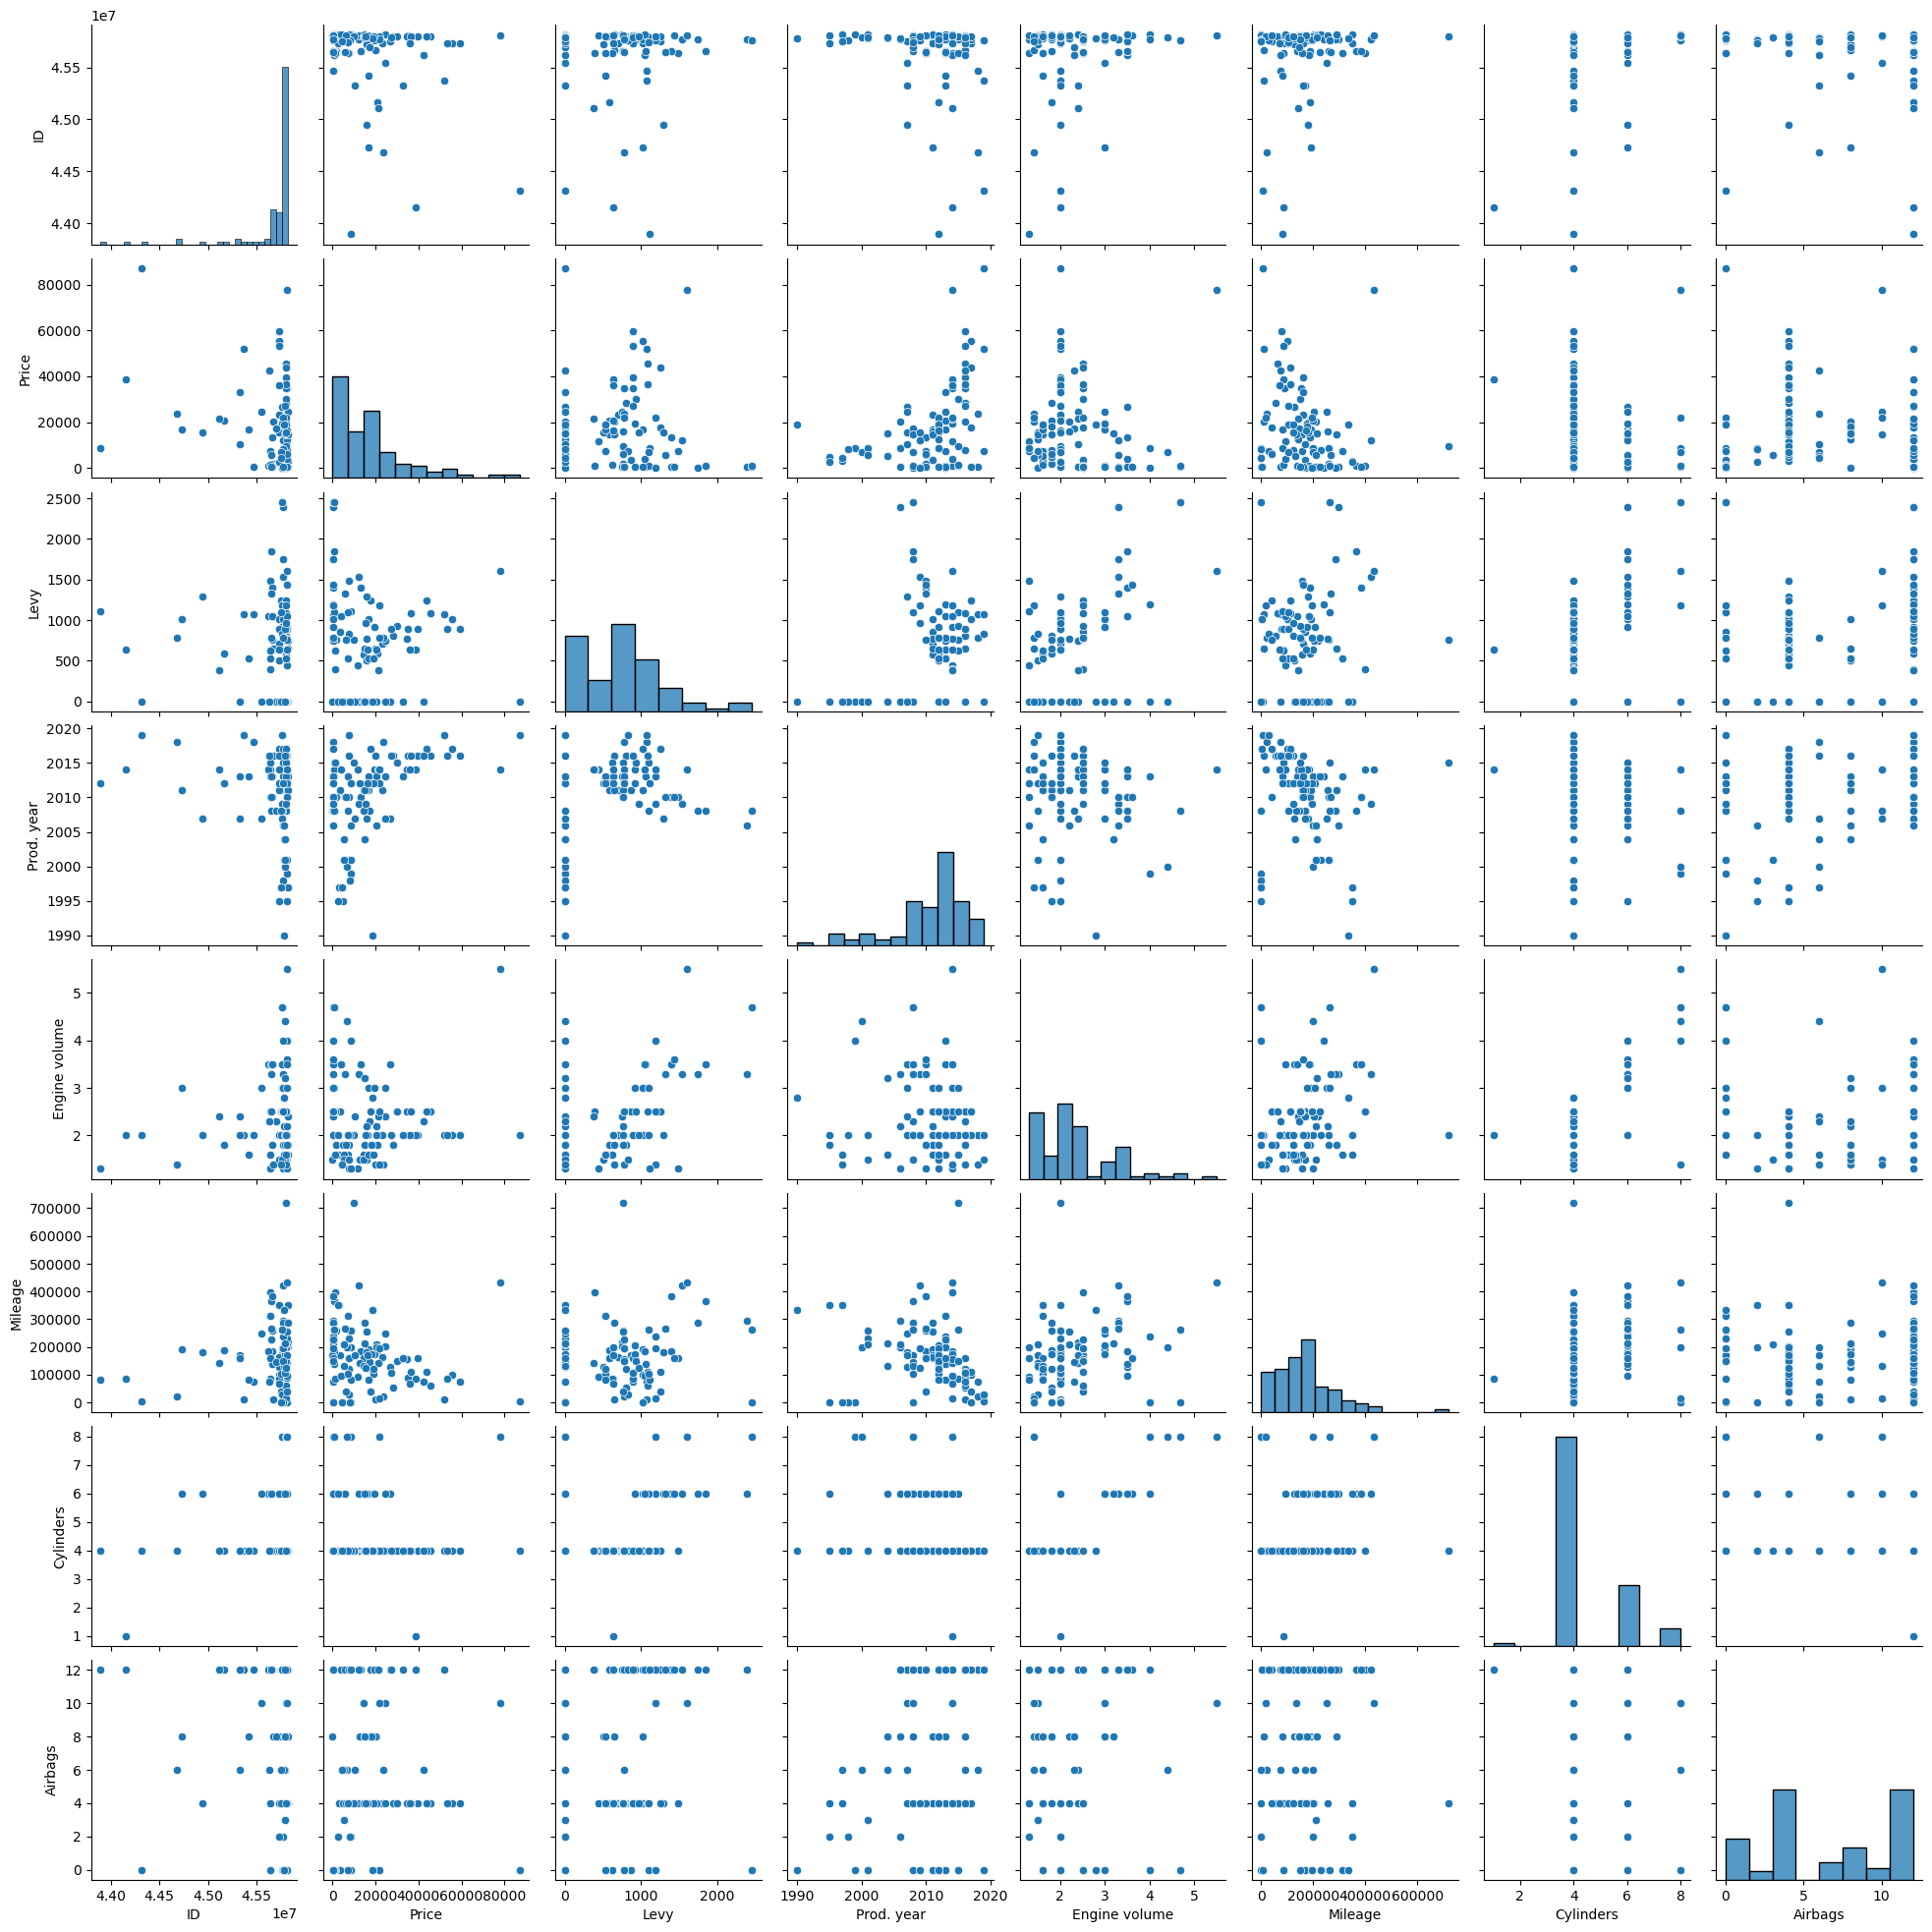

In [28]:
sns.pairplot(data[:100])

<Axes: ylabel='Price'>

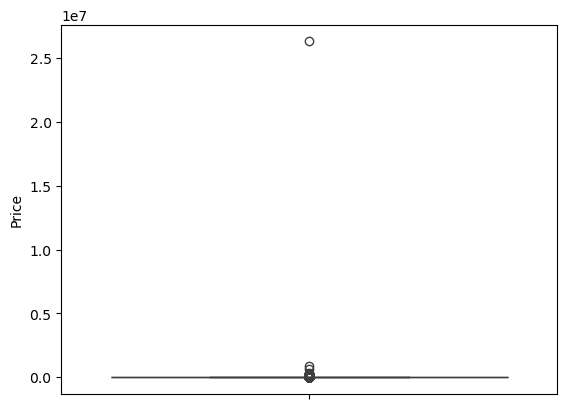

In [29]:
sns.boxplot(data['Price'])

In [30]:
data[data['Price'] > 5e5]

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Wheel,Color,Airbags
1225,45795524,627220,0,MERCEDES-BENZ,G 65 AMG 63AMG,2020,Jeep,Yes,Petrol,6.3,0,8.0,Tiptronic,4x4,Left wheel,Black,12
8541,45761204,872946,2067,LAMBORGHINI,Urus,2019,Universal,Yes,Petrol,4.0,2531,8.0,Tiptronic,4x4,Left wheel,Black,0
16983,45812886,26307500,0,OPEL,Combo,1999,Goods wagon,No,Diesel,1.7,99999,4.0,Manual,Front,Left wheel,Blue,0


<Axes: ylabel='Levy'>

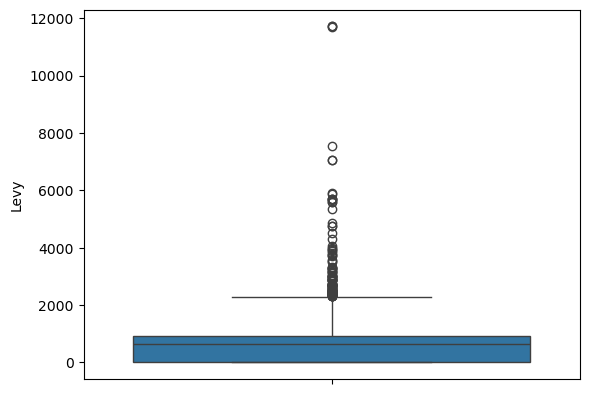

In [32]:
sns.boxplot(data['Levy'])

<Axes: ylabel='Mileage'>

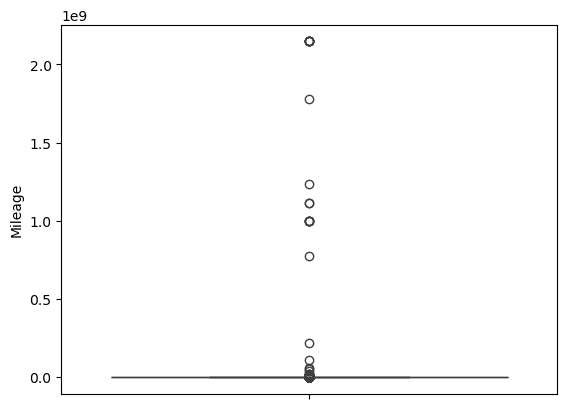

In [33]:
sns.boxplot(data['Mileage'])

In [34]:
def clean_outliers(df, col):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    Lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    df_no_outliers = df[(df[col] >= Lower_bound) & (df[col] <= upper_bound)]
    return df_no_outliers

In [36]:
data = clean_outliers(data, 'Price')
data = clean_outliers(data, 'Mileage')
data = clean_outliers(data, 'Levy')

In [37]:
data.shape

(16657, 17)

6. Target Variable Analysis

· Distribution of Target Variable (for class imbalance, decide if resampling or weighting is needed)
. Relationship with Predictors (scatter plots, box plots against the target)

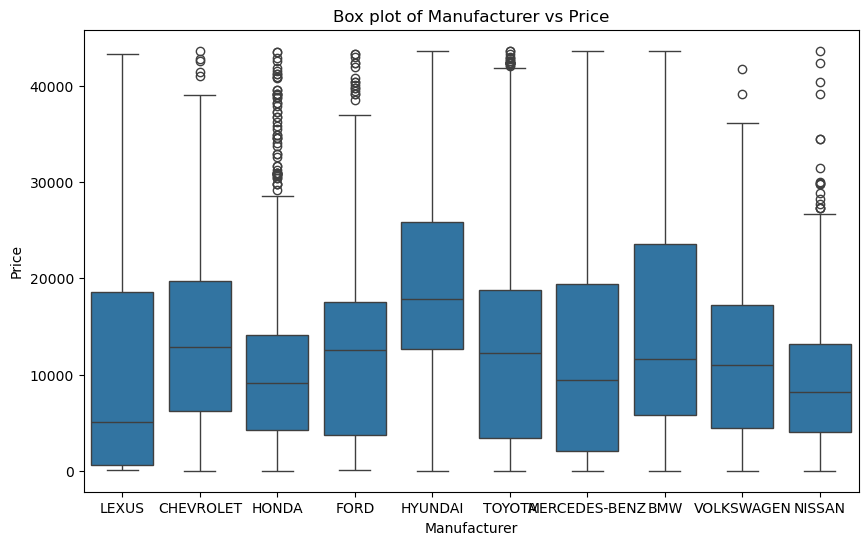

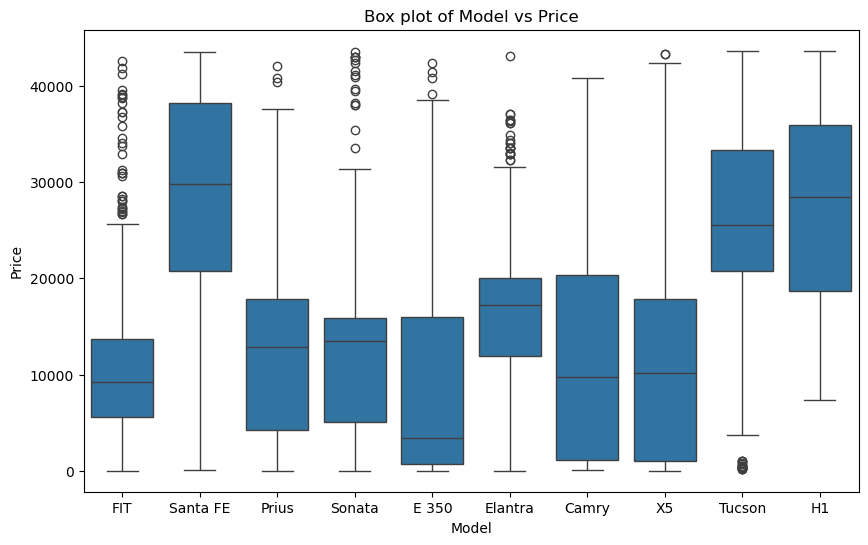

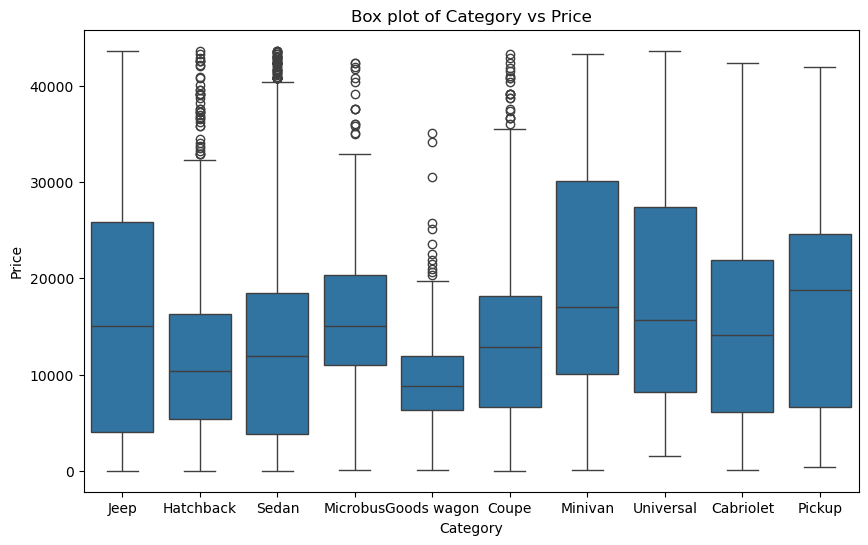

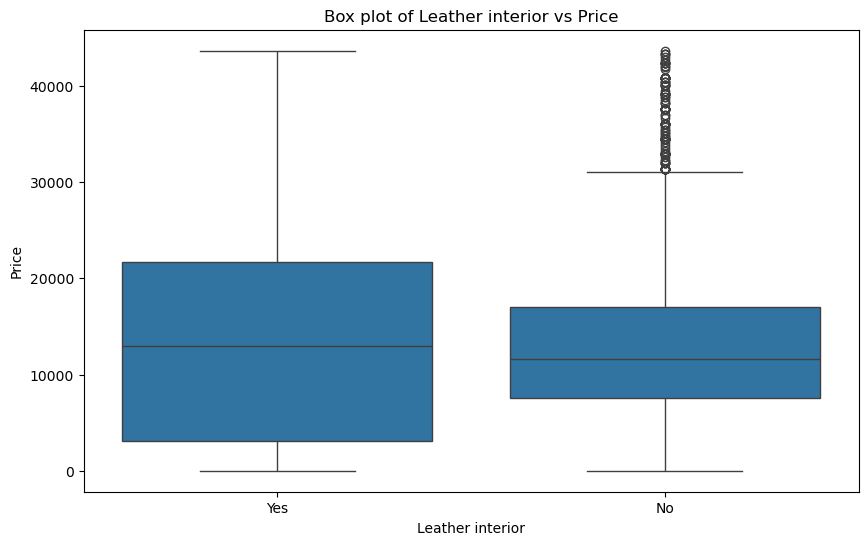

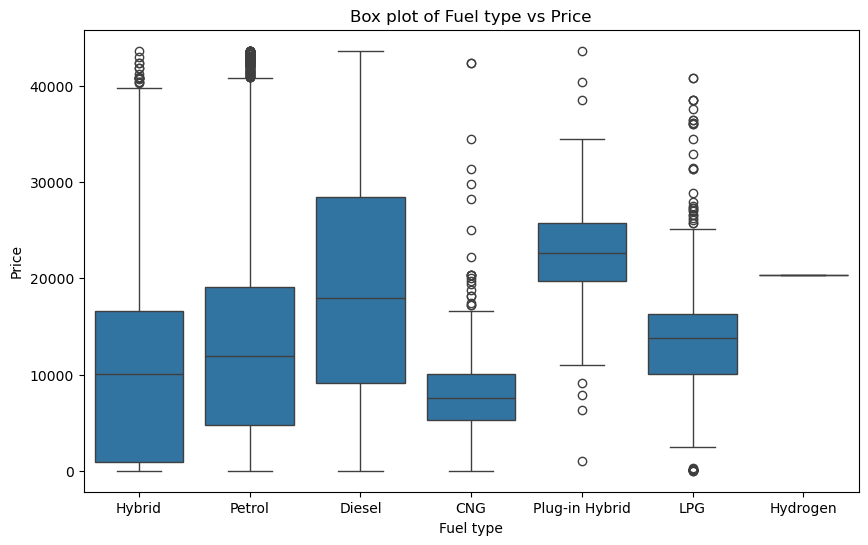

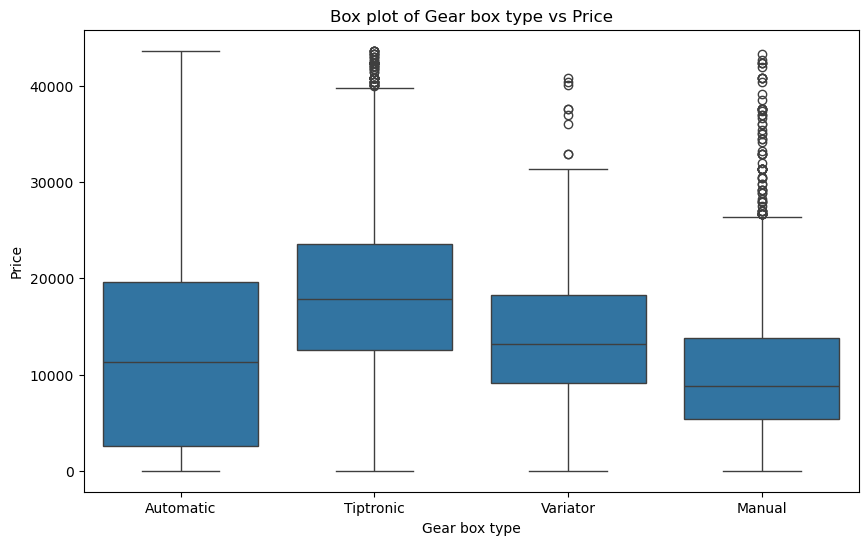

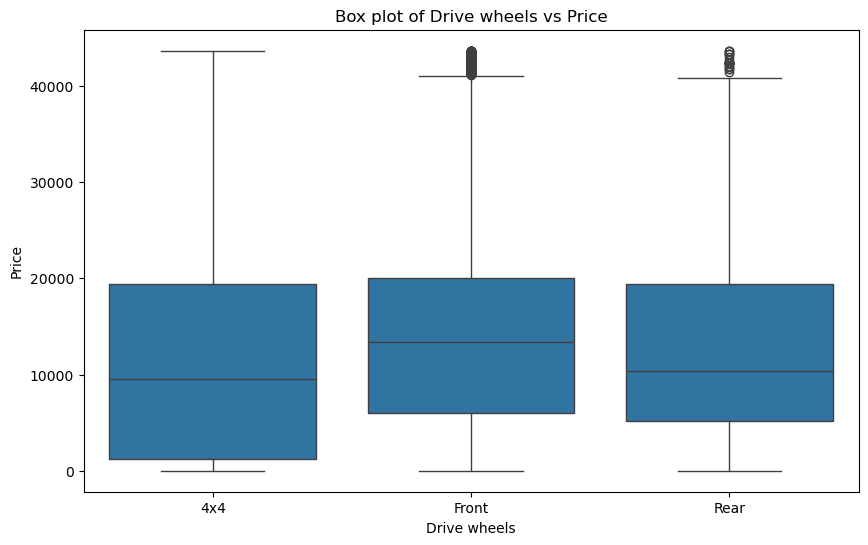

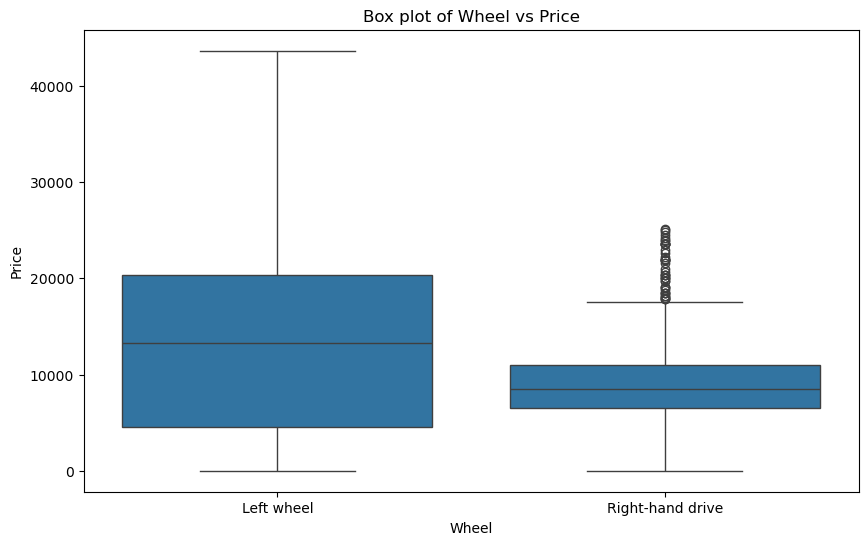

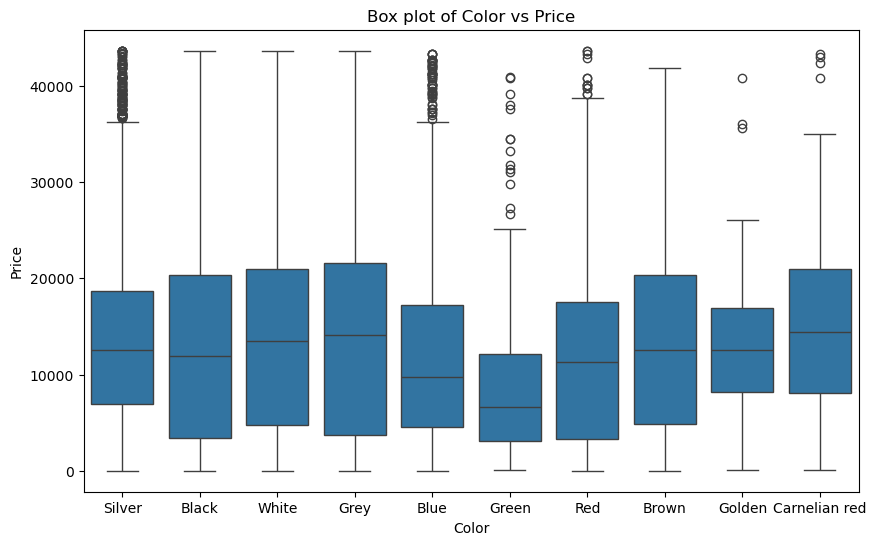

In [38]:
for col in data.select_dtypes('object'):
    top_categories = data[col].value_counts().index[:10]
    filtered_df = data[data[col].isin(top_categories)]

    plt.figure(figsize=(10,6))
    sns.boxplot(x=filtered_df[col], y=filtered_df['Price'])
    plt.title(f'Box plot of {col} vs Price')

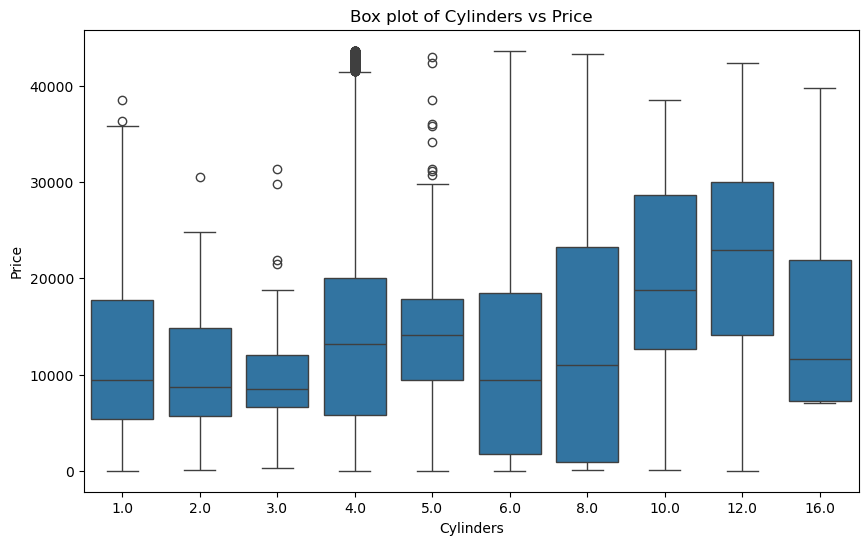

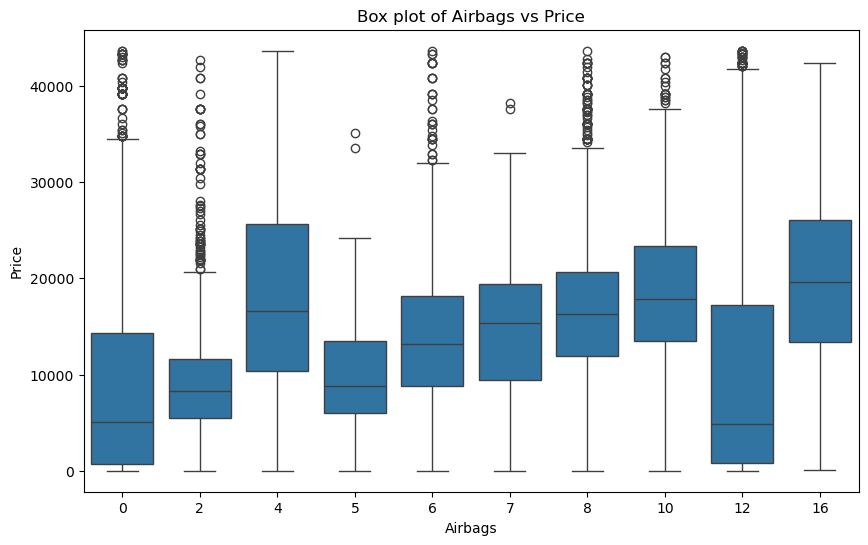

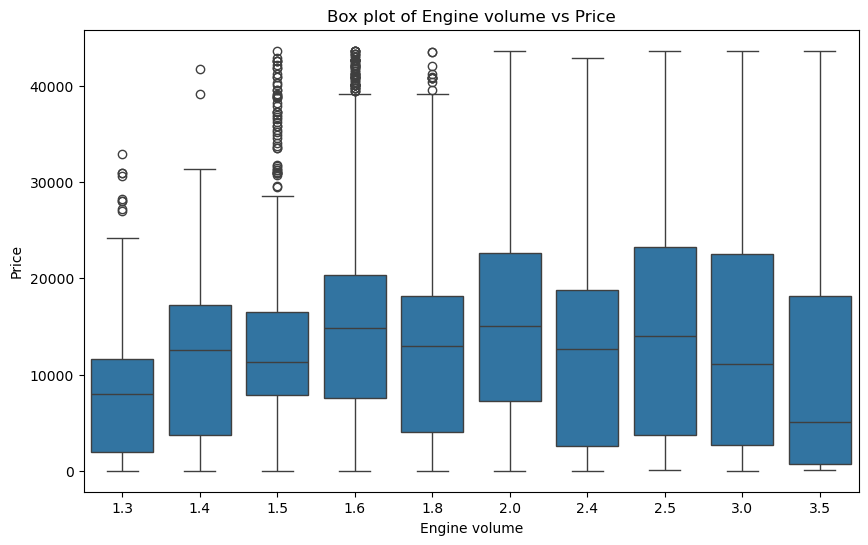

In [42]:
for col in ['Cylinders', 'Airbags', 'Engine volume']:
    top_categories = data[col].value_counts().index[:10]
    filtered_df = data[data[col].isin(top_categories)]

    plt.figure(figsize=(10,6))
    sns.boxplot(x=filtered_df[col], y=filtered_df['Price'])
    plt.title(f'Box plot of {col} vs Price')

# Other notes:

- Can do target encoding (mean encoding) for 'Model', 'Category', 'Manufacturer' and 'Fuel Type'.